---
# Measurement q
---

In [1]:
from monitored_cluster_states.paths import DATA_DIR
from monitored_cluster_states.observables import initialize_data_q
from monitored_cluster_states.plotting import (
    plot_entropy_vs_L,
    plot_CV_vs_DV_fixed_L,
    plot_CV_vs_DV_with_inset,
    plot_vertex_deletion_panels,
    export_vertex_deletion_panels
)

In [2]:
r_fixed, w_fixed = 1.0, 1.0

data_file = DATA_DIR / "vertex_deletion" / f"Raw_Graph_Data_w_{w_fixed:.1f}.pkl"

p_values, dimensions, C_matrix, C_matrix_std, S_matrix, S_matrix_std, S_DV_matrix, S_DV_matrix_std = initialize_data_q(data_file, r=r_fixed)

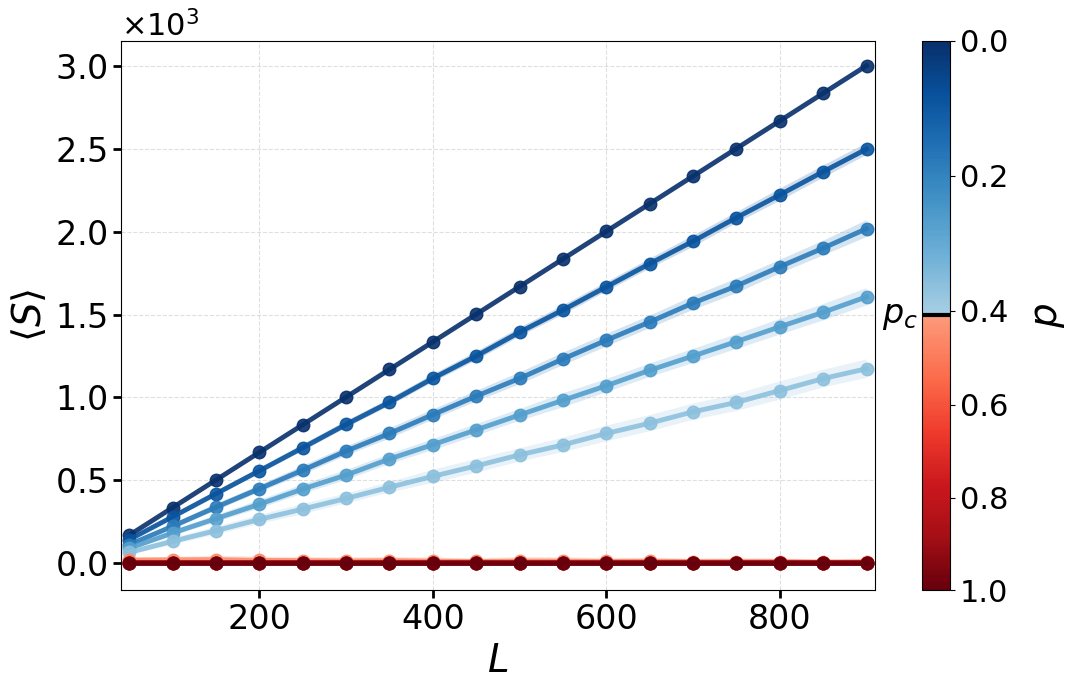

In [7]:
plot_entropy_vs_L(p_values, dimensions, S_matrix, S_matrix_std, p_c=0.4070, vmin=0.0, vmax=1.0)

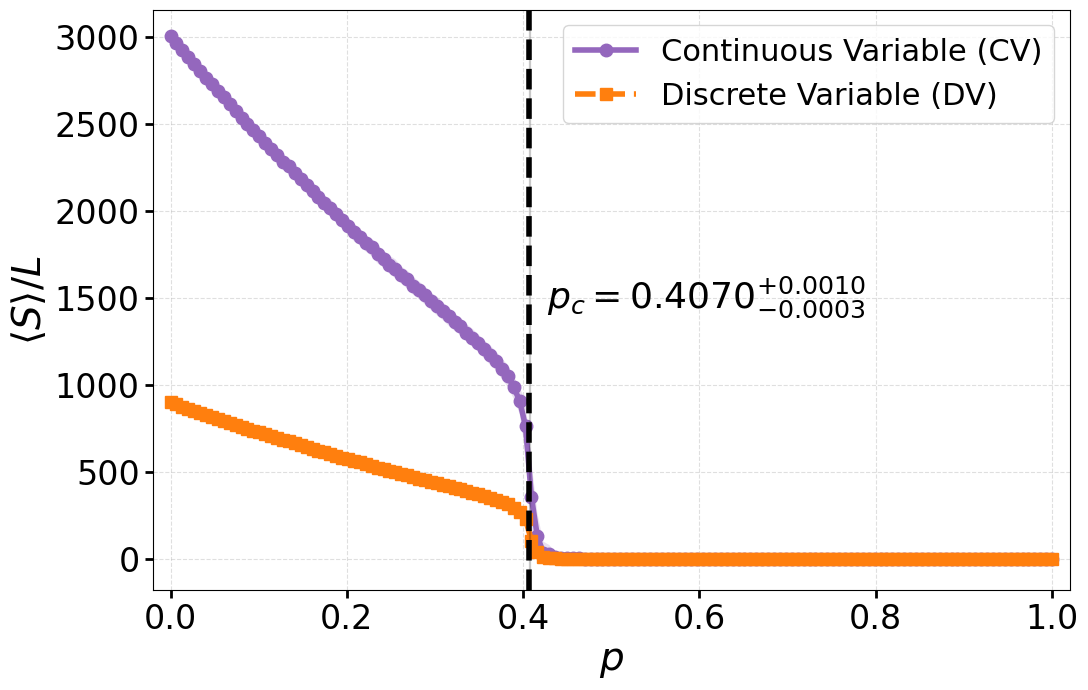

In [6]:
plot_CV_vs_DV_fixed_L(
    p_values, dimensions, S_matrix, S_matrix_std, S_DV_matrix, S_DV_matrix_std,
    target_L=900, p_c=0.4070, p_err_minus=0.0003, p_err_plus=0.0010,
    r_fixed=0.0, w_fixed=1.0
)

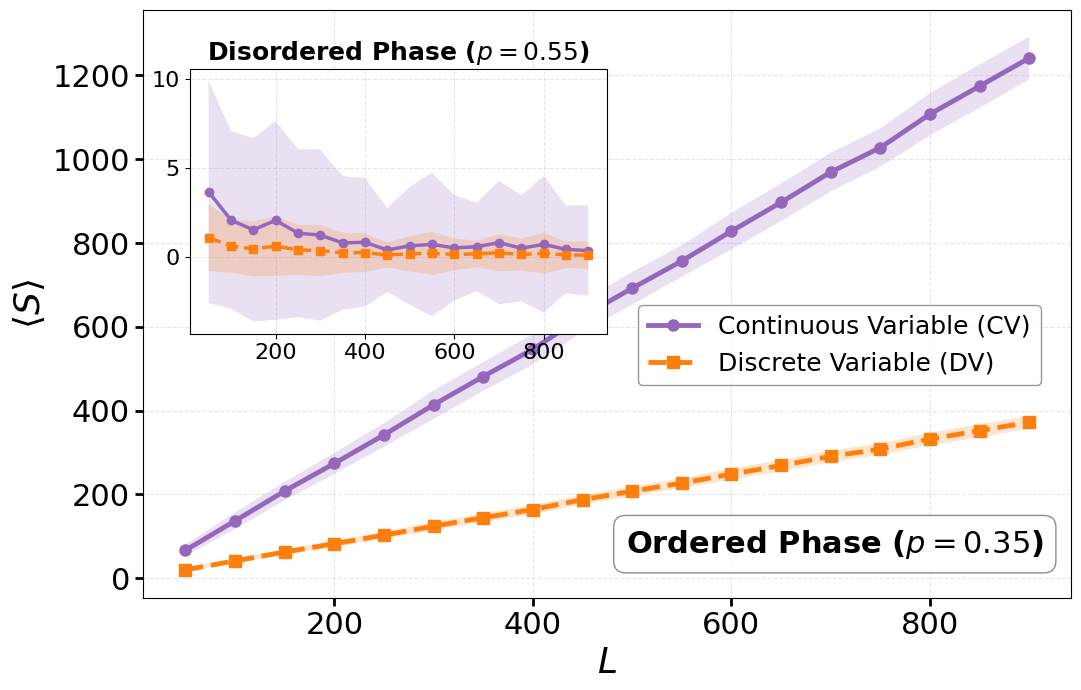

In [8]:
plot_CV_vs_DV_with_inset(
    p_values, dimensions, S_matrix, S_matrix_std, S_DV_matrix, S_DV_matrix_std,
    p_ordered=0.35, p_disordered=0.55
)

C:\Users\Mireia\AppData\Local\Temp\ipykernel_8476\1723145812.py:23: UserWarning: Requested p=0.35; using nearest stored p=0.34899329.
  fig_paper, axes_paper, paper_details = plot_vertex_deletion_panels(
C:\Users\Mireia\AppData\Local\Temp\ipykernel_8476\1723145812.py:23: UserWarning: Requested p=0.7; using nearest stored p=0.69798658.
  fig_paper, axes_paper, paper_details = plot_vertex_deletion_panels(


Bands: ±1 SEM; realisation counts range from 200 to 200.
Stored p: (a) 0.34899329, (b) 0.69798658
Fitted sizes: [50.0, 100.0, 150.0, 200.0, 250.0, 300.0, 350.0, 400.0, 450.0, 500.0, 550.0, 600.0, 650.0, 700.0, 750.0, 800.0, 850.0, 900.0]
DV: S = 0.41446192 L + -0.60552288
CV: S = 1.3829886 L + -2.0205264


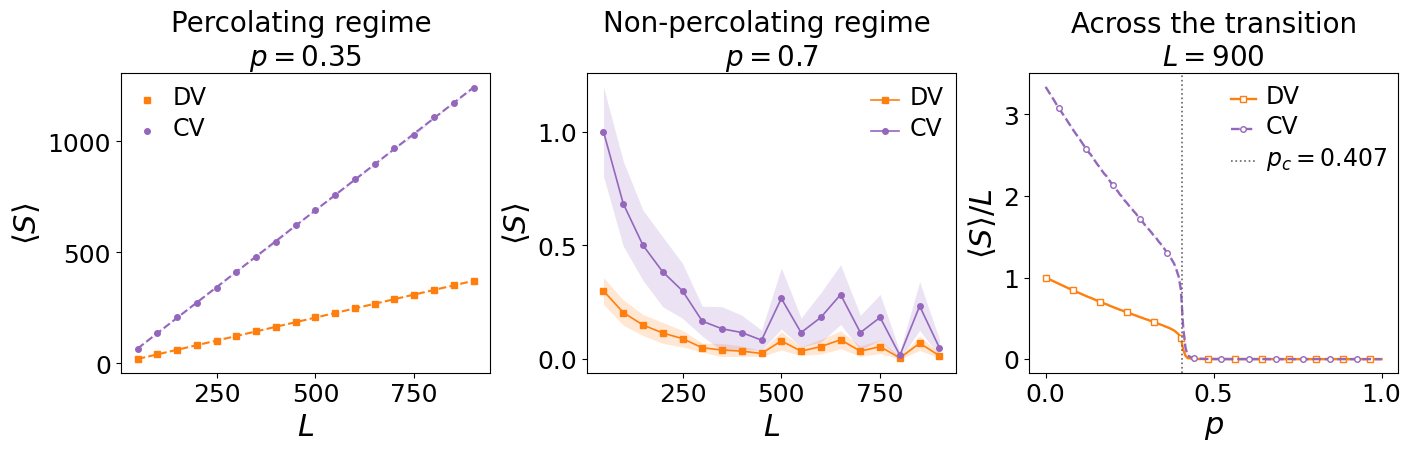

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from monitored_cluster_states.paths import FIGURES_DIR

if w_fixed != 1.0:
    raise ValueError("This figure currently requires w=1; see the spectral-convention note above.")
# Count actual samples in the same (L, p) order as the loader's matrices.
import pickle
with open(data_file, "rb") as handle:
    raw_samples = pickle.load(handle)
n_samples = np.array([
    [len(raw_samples["results"][p][L]["dv_entropies"]) for p in p_values]
    for L in dimensions
])
cv_counts = np.array([
    [len(raw_samples["results"][p][L]["eigenvalues"]) for p in p_values]
    for L in dimensions
])
if not np.array_equal(n_samples, cv_counts):
    raise ValueError("CV and DV sample counts differ; check the raw data.")
del raw_samples, cv_counts

fig_paper, axes_paper, paper_details = plot_vertex_deletion_panels(
    p_values, dimensions, S_matrix, S_matrix_std,
    S_DV_matrix, S_DV_matrix_std,
    n_samples=n_samples, p_ordered=0.35, p_disordered=0.7, p_c=0.4070,
    selected_sizes=[max(dimensions)],  # largest system size only
    fit_min_L=None,       # None fits all available sizes
)
print(f"Bands: ±1 SEM; realisation counts range from {n_samples.min()} to {n_samples.max()}.")
print(f"Stored p: (a) {paper_details['p_ordered']:.8g}, (b) {paper_details['p_disordered']:.8g}")
print("Fitted sizes:", paper_details["fit_sizes"])
for model, fit in paper_details["fits"].items():
    print(f"{model}: S = {fit['slope']:.8g} L + {fit['intercept']:.8g}")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for extension in ("pdf", "svg"):
    fig_paper.savefig(FIGURES_DIR / f"vertex_deletion_three_panel.{extension}", bbox_inches="tight")
plt.show()

Using plotting module: C:\Users\Mireia\Desktop\Master\ICFO\TFM\monitored-cluster-state-simulations\src\monitored_cluster_states\plotting.py


C:\Users\Mireia\AppData\Local\Temp\ipykernel_17308\1131522841.py:12: UserWarning: Requested p=0.35; using stored p=0.34899329.
  paper_results = plotting.export_vertex_deletion_panels(
C:\Users\Mireia\AppData\Local\Temp\ipykernel_17308\1131522841.py:12: UserWarning: Requested p=0.55; using stored p=0.55033557.
  paper_results = plotting.export_vertex_deletion_panels(


Saved three separate PDF figures in: C:\Users\Mireia\Desktop\Master\ICFO\TFM\monitored-cluster-state-simulations\results\figures\separate_panels
Actual probabilities: 0.34899329, 0.55033557
Largest size: L=900
Realisations per point: 200 to 200
DV: S = 0.41446192 L + -0.60552288
CV: S = 1.3829886 L + -2.0205264


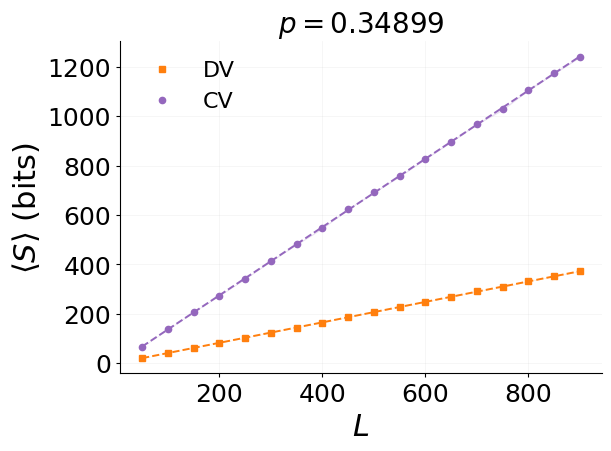

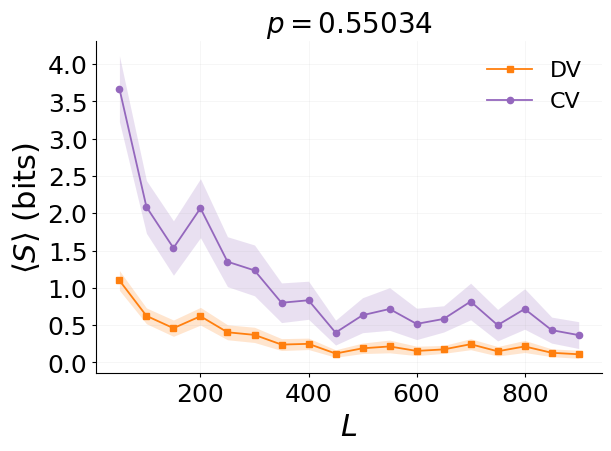

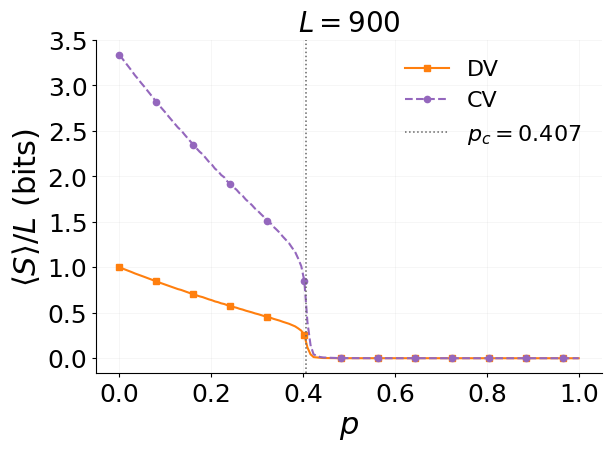

In [3]:
import matplotlib.pyplot as plt
from monitored_cluster_states.paths import FIGURES_DIR

import importlib
import monitored_cluster_states.plotting as plotting

# Reload the file on disk, even if this kernel imported an older version.
plotting = importlib.reload(plotting)
print("Using plotting module:", plotting.__file__)

paper_output_dir = FIGURES_DIR / "separate_panels"
paper_results = plotting.export_vertex_deletion_panels(
    data_file,
    paper_output_dir,
    r=r_fixed,
    p_ordered=0.35,
    p_disordered=0.55,
    p_c=0.4070,
    figsize=(6.0, 4.4),
)

if not isinstance(paper_results, dict):
    raise RuntimeError(
        f"The function in {plotting.__file__} did not return its results dictionary. "
        "Replace that file with the complete updated plotting.py, including its final return block."
    )

print(f"Saved three separate PDF figures in: {paper_output_dir}")
print(f"Actual probabilities: {paper_results['p_ordered']:.8f}, {paper_results['p_disordered']:.8f}")
print(f"Largest size: L={paper_results['L']:g}")
print("Realisations per point:", paper_results["counts"].min(), "to", paper_results["counts"].max())
for model, fit in paper_results["fits"].items():
    print(f"{model}: S = {fit['slope']:.8g} L + {fit['intercept']:.8g}")
plt.show()